# Project: Sample Superstore Sales & Profit Analysis

## Project Title
Superstore Sales, Profitability, and Customer Trend Analysis using Real Business Data

## Project Goal
This project teaches:
* Exploratory Data Analysis (EDA) with real-world business data
* Comprehensive data cleaning following a structured 10-step process
* Data visualization using Python libraries to uncover commercial patterns
* Business insight generation and strategic recommendation formulation

## Dataset Information

| Attribute | Value |
| :--- | :--- |
| Source | Kaggle - Sample Superstore Dataset |
| Records | 9,994 rows |
| Features | 21 columns |
| Key Metrics | Sales, Profit, Quantity, Discount |

# TASK 1: Data Loading & Initial Overview

In [1]:
import pandas as pd

In [2]:
a = pd.read_csv('Superstore.csv', encoding='latin1')
print(a.head())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [3]:
a.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

# TASK 2: Data Preprocessing

### 1. Missing Values

In [4]:
missing_data = a.isnull().sum()
missing_data = missing_data[missing_data > 0]

if missing_data.empty:
    print("No missing values found in the dataset.")
else:
    display(missing_data)

No missing values found in the dataset.


### 2. Duplicates

In [5]:
# Check for duplicate rows in the dataset
duplicate_count = a.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

Total duplicate rows: 0


### 3. Correct Data Types

In [6]:
# Convert Order Date and Ship Date to datetime format
a['Order Date'] = pd.to_datetime(a['Order Date'])
a['Ship Date'] = pd.to_datetime(a['Ship Date'])

# Verify data types after conversion
print(a[['Order Date', 'Ship Date']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [7]:
# Trim leading and trailing whitespaces from text columns
text_cols = a.select_dtypes(include=['object']).columns
for col in text_cols:
    a[col] = a[col].astype(str).str.strip()

# Pad postal codes to 5 digits to prevent truncation
if 'Postal_Code' in a.columns:
    a['Postal_Code'] = a['Postal_Code'].astype(str).str.split('.').str[0].str.zfill(5)

### 4. Handle Incorrect Values

In [8]:
# Check for logical correctness in numerical ranges (e.g., negative quantities or prices)
incorrect_sales = (a['Sales'] < 0).sum()
incorrect_quantity = (a['Quantity'] <= 0).sum()
incorrect_discount = ((a['Discount'] < 0) | (a['Discount'] > 1)).sum()

print(f"Negative/Invalid Sales rows: {incorrect_sales}")
print(f"Invalid Quantity rows (<= 0): {incorrect_quantity}")
print(f"Invalid Discount rows (outside 0-1): {incorrect_discount}")
print("Conclusion: No illogical or incorrect values found.")

Negative/Invalid Sales rows: 0
Invalid Quantity rows (<= 0): 0
Invalid Discount rows (outside 0-1): 0
Conclusion: No illogical or incorrect values found.


### 5. Handle Outliers

In [9]:
# View summary statistics to identify high/low value spreads (outliers)
display(a[['Sales', 'Quantity', 'Discount', 'Profit']].describe())

# Note on Outliers:
# In retail datasets like Superstore, extreme high sales and negative profits (losses)
# represent legitimate high-value corporate orders or heavy discounts, so they are kept for realistic analysis.
print("Outliers reviewed via statistical distribution.")

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


Outliers reviewed via statistical distribution.


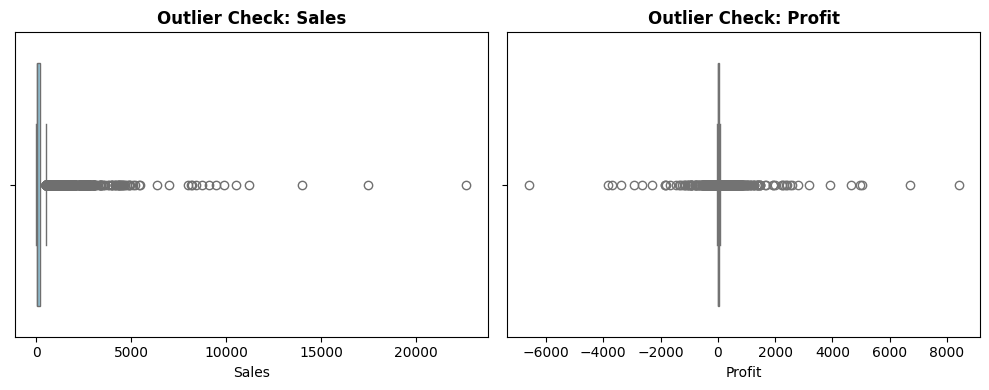

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))

# Sales Outlier Box Plot
plt.subplot(1, 2, 1)
sns.boxplot(x=a['Sales'], color='skyblue')
plt.title('Outlier Check: Sales', fontsize=12, fontweight='bold')

# Profit Outlier Box Plot
plt.subplot(1, 2, 2)
sns.boxplot(x=a['Profit'], color='lightgreen')
plt.title('Outlier Check: Profit', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretation:**
* **Sales Box Plot:** Displays a considerable number of upper-bound outliers, representing high-value bulk orders or corporate purchases that deviate from standard retail transactions.
* **Profit Box Plot:** Highlights severe negative outliers (heavy losses), indicating transactions where excessive discounting or logistical costs resulted in financial loss.

### 6. Rename Columns

In [11]:
# Check current column names
print("Current columns:")
print(a.columns.tolist())

# Optional: If you want to replace hyphens or spaces for easier coding later,
# you can rename specific columns, or keep them as is if they are already clear.
# Example: a.rename(columns={'Sub-Category': 'Sub_Category', 'Postal Code': 'Postal_Code'}, inplace=True)

print("\nColumn names verified. No major renaming required as names are descriptive.")

Current columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Column names verified. No major renaming required as names are descriptive.


In [12]:
# Rename columns to remove spaces and hyphens for cleaner coding
a.rename(columns={
    'Sub-Category': 'Sub_Category',
    'Postal Code': 'Postal_Code'
}, inplace=True)

# Verify the updated column names
print("Updated columns:")
print(a.columns.tolist())

Updated columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product ID', 'Category', 'Sub_Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


### 7. Create New Columns (Feature Engineering)

In [13]:
# Extract all date-based features in one comprehensive step
a['Order Year'] = a['Order Date'].dt.year
a['Order Month'] = a['Order Date'].dt.month_name()
a['Order YearMonth'] = a['Order Date'].dt.to_period('M')
a['Order Day'] = a['Order Date'].dt.day
a['Order Day of Week'] = a['Order Date'].dt.day_name()

# Preview the original Order Date alongside all new feature columns
display(a[['Order Date', 'Order Year', 'Order Month', 'Order YearMonth', 'Order Day', 'Order Day of Week']].head())

,Order Date,Order Year,Order Month,Order YearMonth,Order Day,Order Day of Week
0,2016-11-08,2016,November,2016-11,8,Tuesday
1,2016-11-08,2016,November,2016-11,8,Tuesday
2,2016-06-12,2016,June,2016-06,12,Sunday
3,2015-10-11,2015,October,2015-10,11,Sunday
4,2015-10-11,2015,October,2015-10,11,Sunday


In [14]:
# Engineer financial features
a['Unit Price'] = a['Sales'] / a['Quantity']
a['Profit Margin'] = a['Profit'] / a['Sales']

# Preview the new financial features
display(a[['Sales', 'Quantity', 'Profit', 'Unit Price', 'Profit Margin']].head())

,Sales,Quantity,Profit,Unit Price,Profit Margin
0,261.9600,2,41.9136,130.9800,0.1600
1,731.9400,3,219.5820,243.9800,0.3000
2,14.6200,2,6.8714,7.3100,0.4700
3,957.5775,5,-383.0310,191.5155,-0.4000
4,22.3680,2,2.5164,11.1840,0.1125


# TASK 3: Exploratory Data Analysis (EDA)
In this step, we explore the dataset to understand individual columns, compute key numerical statistics (mean, median, min, max, standard deviation), and analyze categorical frequencieS

## 1. Column-by-Column Data Types & Classifications

To perform effective Exploratory Data Analysis (EDA), we must first classify our columns:

| Column Name | Pandas Data Type | Variable Classification | Semantic Description |
| :--- | :--- | :--- | :--- |
| **Row ID** | int64 | Qualitative (Identifier) | Unique row number for each record. |
| **Order ID** | object (string) | Qualitative (Identifier) | Unique identification number assigned to each order. |
| **Order Date** | datetime64[ns] | Temporal | The exact date when the order was placed. |
| **Ship Date** | datetime64[ns] | Temporal | The exact date when the order was shipped. |
| **Ship Mode** | object (string) | Qualitative (Categorical) | The shipping method used (e.g., Standard Class, Second Class, First Class). |
| **Customer ID** | object (string) | Qualitative (Identifier) | Unique identifier linking the transaction to a specific customer. |
| **Customer Name** | object (string) | Qualitative (Categorical) | Full name of the customer making the purchase. |
| **Segment** | object (string) | Qualitative (Categorical) | Customer market segment (e.g., Consumer, Corporate, Home Office). |
| **Country** | object (string) | Qualitative (Categorical) | Country where the order was placed (United States). |
| **City** | object (string) | Qualitative (Categorical) | City where the order was delivered. |
| **State** | object (string) | Qualitative (Categorical) | State where the order was delivered. |
| **Postal_Code** | object / int64 | Qualitative (Identifier) | Postal code of the delivery location. |
| **Region** | object (string) | Qualitative (Categorical) | Geographical sales region (e.g., West, East, Central, South). |
| **Product ID** | object (string) | Qualitative (Identifier) | Unique product identification code. |
| **Category** | object (string) | Qualitative (Categorical) | High-level product category (e.g., Furniture, Office Supplies, Technology). |
| **Sub_Category** | object (string) | Qualitative (Categorical) | Specific sub-division of the product category (e.g., Binders, Phones). |
| **Product Name** | object (string) | Qualitative (Categorical) | Full descriptive name of the item purchased. |
| **Sales** | float64 | Quantitative (Continuous) | Total monetary sales value generated by the line item. |
| **Quantity** | int64 | Quantitative (Discrete) | Number of units purchased in the order line. |
| **Discount** | float64 | Quantitative (Continuous) | Discount percentage applied to the product (ranging from 0 to 1). |
| **Profit** | float64 | Quantitative (Continuous) | Net profit or loss resulting from the order line. |
| **Order Year** | int32 | Temporal / Quantitative | Extracted year of the order date. |
| **Order Month** | object (string) | Temporal / Qualitative | Extracted name of the month when the order was placed. |
| **Order YearMonth** | period[M] | Temporal | Combined year and month period format. |
| **Order Day** | int32 | Temporal / Quantitative | Extracted day of the month. |
| **Order Day of Week** | object (string) | Temporal / Qualitative | Name of the weekday the order was placed (e.g., Monday, Tuesday). |
| **Unit Price** | float64 | Quantitative (Continuous) | Calculated price per single unit (Sales / Quantity). |
| **Profit Margin** | float64 | Quantitative (Continuous) | Calculated profitability ratio (Profit / Sales). |

###1. Understand individual columns and their data types

In [15]:
print("--- Column Data Types & Info ---")
print(a.dtypes)

--- Column Data Types & Info ---
Row ID                        int64
Order ID                     object
Order Date           datetime64[ns]
Ship Date            datetime64[ns]
Ship Mode                    object
Customer ID                  object
Customer Name                object
Segment                      object
Country                      object
City                         object
State                        object
Postal_Code                   int64
Region                       object
Product ID                   object
Category                     object
Sub_Category                 object
Product Name                 object
Sales                       float64
Quantity                      int64
Discount                    float64
Profit                      float64
Order Year                    int32
Order Month                  object
Order YearMonth           period[M]
Order Day                     int32
Order Day of Week            object
Unit Price                  flo

###2. Analyze numerical data (Mean, Median/50%, Min, Max, Std Dev)

In [16]:
print("\n--- Detailed Numerical Statistics ---")
num_cols = ['Sales', 'Quantity', 'Discount', 'Profit', 'Unit Price', 'Profit Margin']
# Computing mean, min, max, std directly
summary_stats = a[num_cols].agg(['mean', 'median', 'min', 'max', 'std'])
display(summary_stats)


--- Detailed Numerical Statistics ---


,Sales,Quantity,Discount,Profit,Unit Price,Profit Margin
mean,229.858001,3.789574,0.156203,28.656896,60.919569,0.120314
median,54.490000,3.000000,0.200000,8.666500,16.270000,0.270000
min,0.444000,1.000000,0.000000,-6599.978000,0.336000,-2.750000
max,22638.480000,14.000000,0.800000,8399.976000,3773.080000,0.500000
std,623.245101,2.225110,0.206452,234.260108,142.927440,0.466754


###3. Analyze categorical data (Count and most common categories)

In [17]:
print("\n--- Categorical Data Analysis ---")
print("Category Counts:")
display(a['Category'].value_counts())

print("\nTop 5 Sub-Categories:")
display(a['Sub_Category'].value_counts().head(5))

print("\nTop 5 Regions by Order Count:")
display(a['Region'].value_counts().head(5))


--- Categorical Data Analysis ---
Category Counts:


,count
Category,
Office Supplies,6026
Furniture,2121
Technology,1847



Top 5 Sub-Categories:


,count
Sub_Category,
Binders,1523
Paper,1370
Furnishings,957
Phones,889
Storage,846



Top 5 Regions by Order Count:


,count
Region,
West,3203
East,2848
Central,2323
South,1620


# STEP 4: Data Visualization

In this step, we represent our data using charts and graphs to uncover visual patterns, category performance, regional sales, and distribution spreads across the Superstore dataset.

## 1. Category-wise and Region-wise Sales Analysis (Bar Chart)
**Library Used:** Matplotlib & Seaborn

**Objective:** Compare total sales across different product categories and geographic regions.

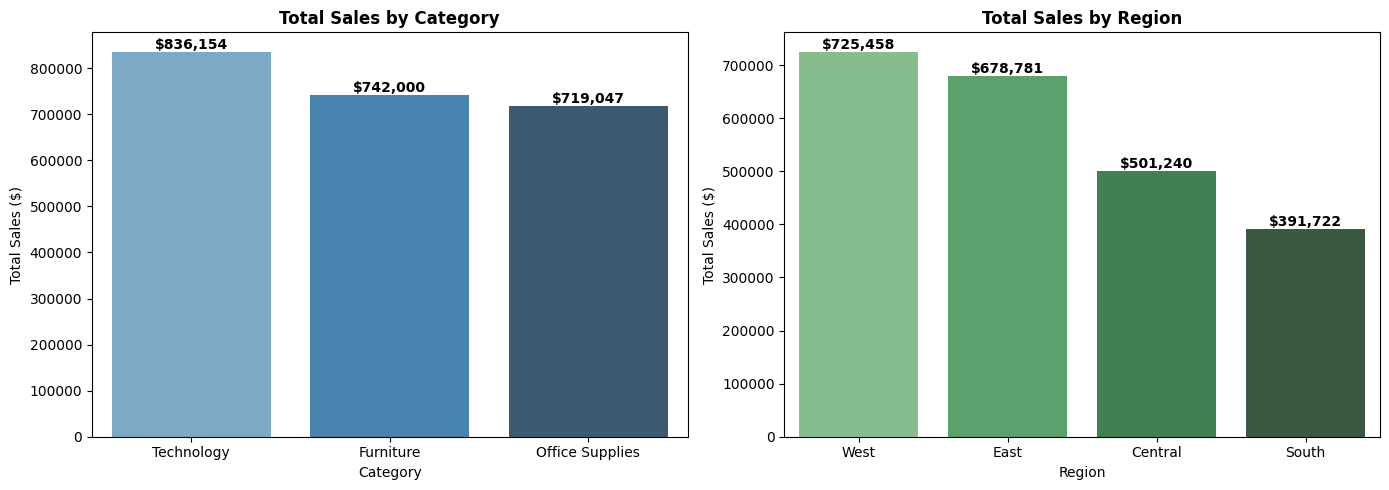

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Figure Size
plt.figure(figsize=(14, 5))

# Subplot 1: Category Sales
plt.subplot(1, 2, 1)
category_sales = a.groupby('Category')['Sales'].sum().sort_values(ascending=False).reset_index()
ax1 = sns.barplot(x='Category', y='Sales', data=category_sales, palette='Blues_d', hue='Category', legend=False)
plt.title('Total Sales by Category', fontsize=12, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Total Sales ($)')

# Add exact values on top of each bar
for p in ax1.patches:
    ax1.annotate(f"${p.get_height():,.0f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5),
                textcoords='offset points', fontsize=10, fontweight='bold')

# Subplot 2: Regional Sales
plt.subplot(1, 2, 2)
region_sales = a.groupby('Region')['Sales'].sum().sort_values(ascending=False).reset_index()
ax2 = sns.barplot(x='Region', y='Sales', data=region_sales, palette='Greens_d', hue='Region', legend=False)
plt.title('Total Sales by Region', fontsize=12, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')

# Add exact values on top of each bar
for p in ax2.patches:
    ax2.annotate(f"${p.get_height():,.0f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5),
                textcoords='offset points', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretation:**
* Category: Technology and Furniture contribute major sales shares, but sales share alone does not establish which category is more profitable, as high sales can often be offset by heavy discounting.
* **Region:** The West and East regions dominate overall sales, indicating strong regional market demand compared to Central and South.

## 2. Monthly Sales Trend Over Time (Line Chart)
**Library Used:** Matplotlib & Seaborn

**Objective:** Show sales trends and fluctuations over time.

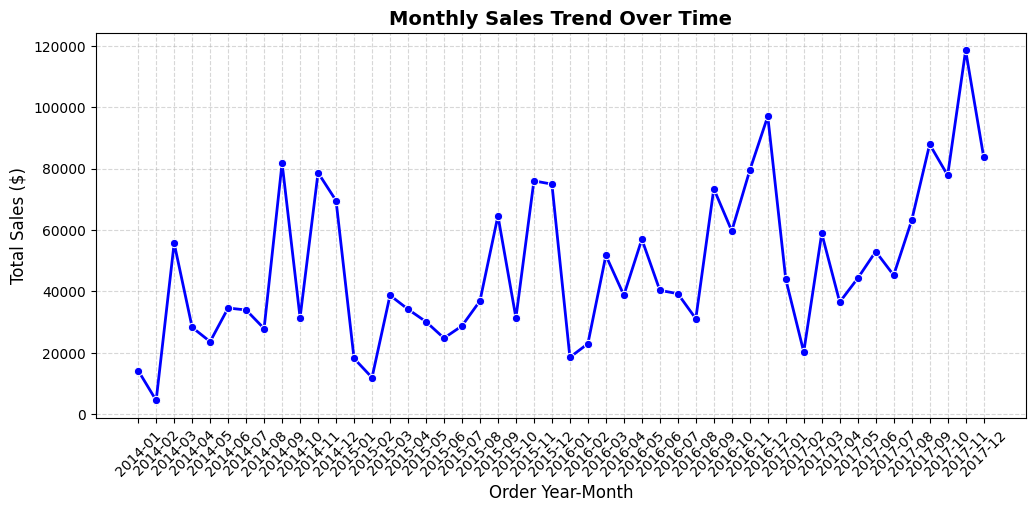

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Convert Order YearMonth to proper string format and sort chronologically
monthly_sales = a.groupby(a['Order YearMonth'].astype(str))['Sales'].sum().reset_index()
monthly_sales = monthly_sales.sort_values('Order YearMonth')

sns.lineplot(data=monthly_sales, x='Order YearMonth', y='Sales', marker='o', color='b', linewidth=2)
plt.title('Monthly Sales Trend Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Order Year-Month', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Interpretation:**
* The line chart reveals cyclical fluctuations in monthly sales, with noticeable sales spikes towards the end of each calendar year, indicating seasonal holiday or year-end purchasing surges.


## 3. Distribution of Sales (Histogram)
**Library Used:** Seaborn & Matplotlib

**Objective:** Show the frequency and distribution range of order sales values.

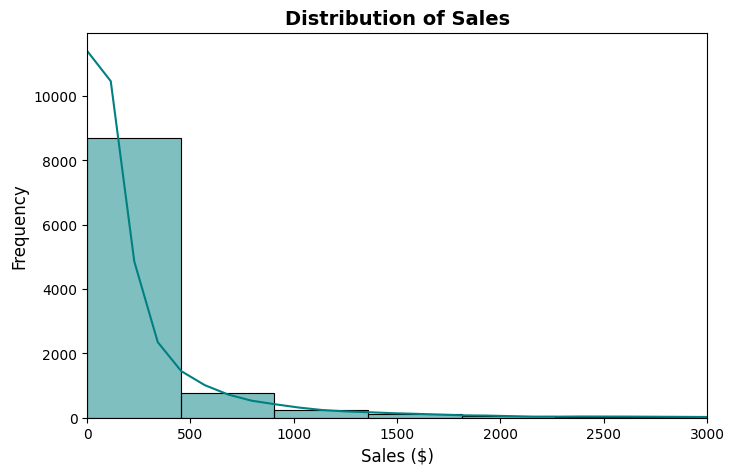

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(a['Sales'], bins=50, kde=True, color='teal')
plt.title('Distribution of Sales', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xlim(0, 3000)  # Focusing on the core distribution range
plt.show()

**Interpretation:**
* The histogram shows a right-skewed distribution where the majority of orders fall within the lower sales range (under $500), indicating high-frequency lower-value retail transactions.

## 4. Box Plot for Outlier Detection (Sales & Profit)
**Library Used:** Seaborn & Matplotlib

**Objective:** Identify spread, data distribution, and outlier/extreme values.

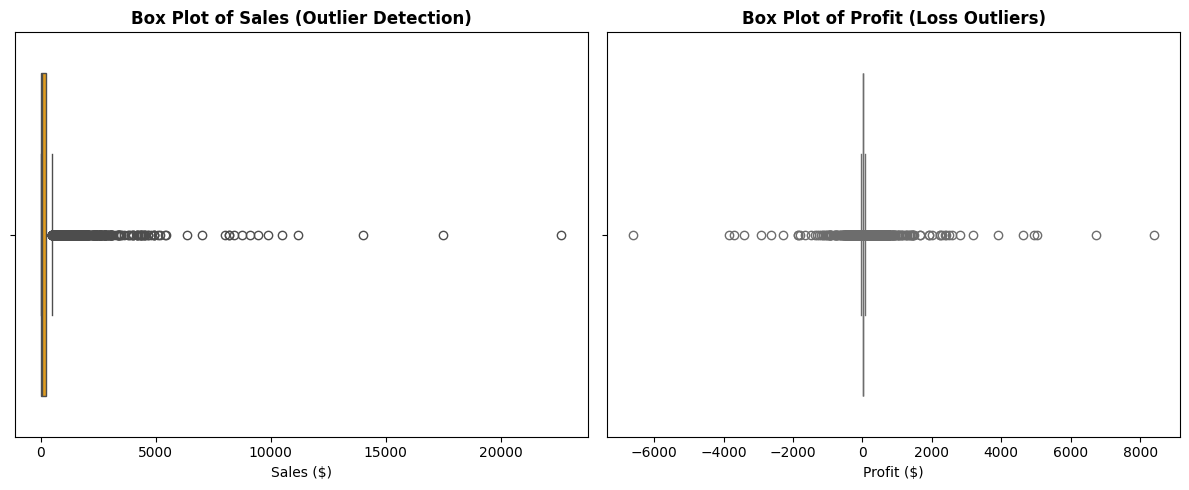

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Subplot 1: Sales Boxplot
plt.subplot(1, 2, 1)
sns.boxplot(x=a['Sales'], color='orange')
plt.title('Box Plot of Sales (Outlier Detection)', fontsize=12, fontweight='bold')
plt.xlabel('Sales ($)')

# Subplot 2: Profit Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=a['Profit'], color='salmon')
plt.title('Box Plot of Profit (Loss Outliers)', fontsize=12, fontweight='bold')
plt.xlabel('Profit ($)')

plt.tight_layout()
plt.show()

**Interpretation:**
* **Sales Box Plot:** Reveals numerous upper-bound outliers representing large corporate/bulk orders.
* **Profit Box Plot:** Highlights critical negative outliers (heavy losses) caused by aggressive discounting strategies.

## 5. Scatter Plot (Sales vs. Profit Relationship)
**Library Used:** Seaborn & Matplotlib

**Objective:** Show the relationship and pattern between two numerical variables (Sales and Profit).

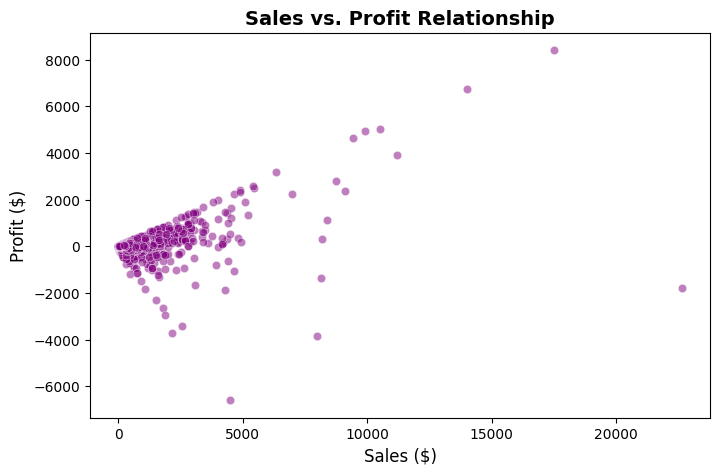

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=a, x='Sales', y='Profit', alpha=0.5, color='purple')
plt.title('Sales vs. Profit Relationship', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)', fontsize=12)
plt.ylabel('Profit ($)', fontsize=12)
plt.show()

**Interpretation:**
* The scatter plot illustrates how sales revenue relates to profitability. While most transactions yield positive returns, a significant cluster of orders drops below the zero-profit line, highlighting the negative impact of high discounts.

## 6. Sales Share by Product Category (Interactive Pie Chart)
**Library Used:** Plotly Express

**Objective:** Show the proportional share of sales contributed by each product category.

In [23]:
import plotly.express as px

# Category-wise sales aggregation
category_sales = a.groupby('Category')['Sales'].sum().reset_index()

# Plotly Interactive Pie/Donut Chart Creation
fig = px.pie(category_sales,
             values='Sales',
             names='Category',
             title='Sales Share Distribution by Category',
             hole=0.4, # Donut chart style for better visual appeal
             color_discrete_sequence=px.colors.qualitative.Set3)

fig.update_traces(textposition='inside', textinfo='percent+label')
fig.show()

**Interpretation:**
- The interactive pie chart demonstrates that Technology and Furniture hold the major percentage share of overall revenue. However, sales share alone does not establish which category is more profitable without factoring in product-level costs and discounts.

## 7. Correlation Heatmap of Numerical Features
**Library Used:** Seaborn & Matplotlib

**Objective:** Show the correlation and linear relationships across numerical columns.

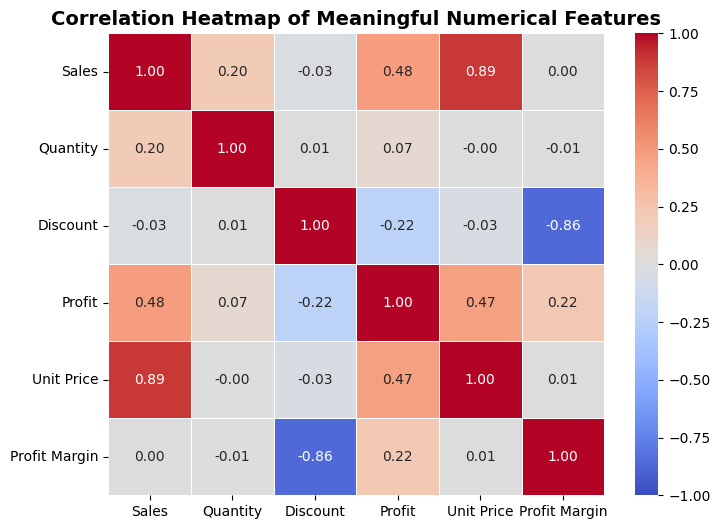

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
meaningful_cols = ['Sales', 'Quantity', 'Discount', 'Profit', 'Unit Price', 'Profit Margin']
correlation_matrix = a[meaningful_cols].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Meaningful Numerical Features', fontsize=14, fontweight='bold')
plt.show()

**Interpretation:**
* The correlation heatmap maps out linear interactions across features. It confirms expected positive interactions, while highlighting how specific variables relate across the dataset.

## 8 Profit by Category and Sub-Category (Bar Chart)
**Library Used:** Seaborn & Matplotlib

**Objective:** Identify which product sub-categories generate the highest profit and which generate losses across different categories.

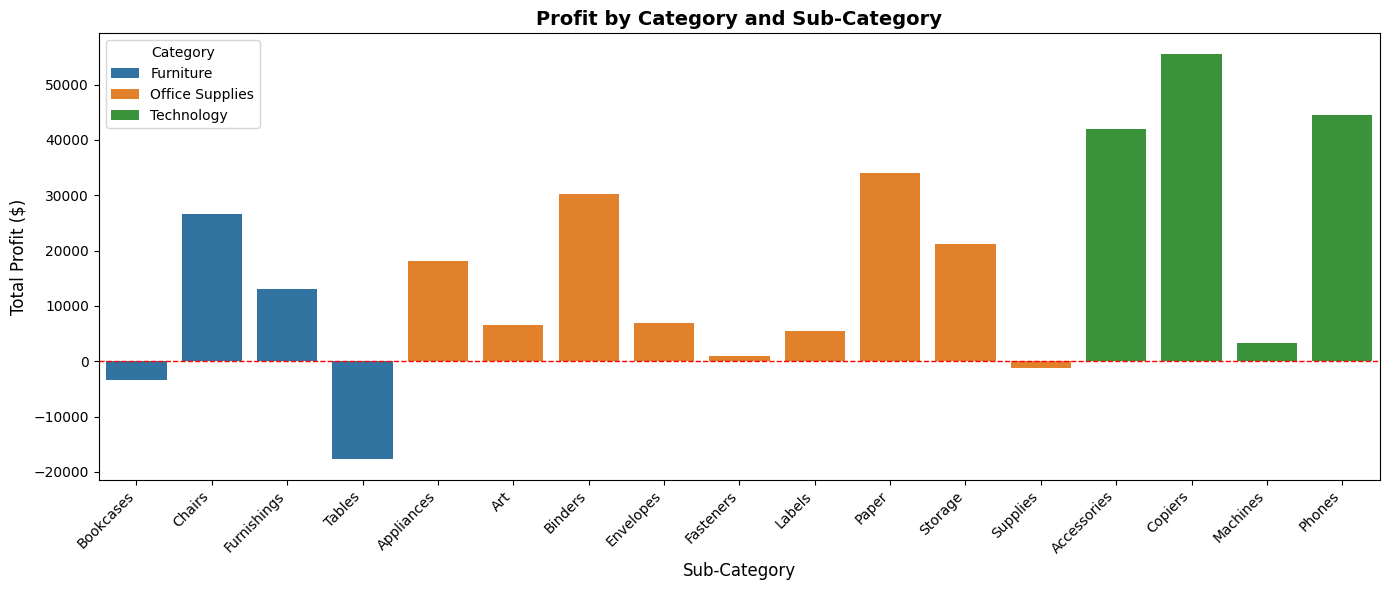

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))
sub_profit = a.groupby(['Category', 'Sub_Category'])['Profit'].sum().reset_index()

ax = sns.barplot(data=sub_profit, x='Sub_Category', y='Profit', hue='Category', dodge=False)
plt.title('Profit by Category and Sub-Category', fontsize=14, fontweight='bold')
plt.xlabel('Sub-Category', fontsize=12)
plt.ylabel('Total Profit ($)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='red', linestyle='--', linewidth=1) # Zero profit line to distinguish profit vs loss
plt.legend(title='Category')
plt.tight_layout()
plt.show()

**Interpretation:**
* Profit vs. Loss Breakdown: The bar chart illustrates the net profit and loss across various product sub-categories. While most sub-categories generate positive returns (with Copiers, Phones, and Accessories showing the highest profits), categories like Tables, Bookcases, and Supplies suffer heavy financial losses (dropping below the red zero-profit line).

* Business Impact: This highlights that high-sales categories do not automatically guarantee profitability, as aggressive discounting on items like tables and bookcases severely erodes margins.

## 9 Discount vs. Profit Analysis
**Library Used:** Seaborn & Matplotlib  
**Objective:** Use a scatter plot to examine how discount levels relate to profit and loss.

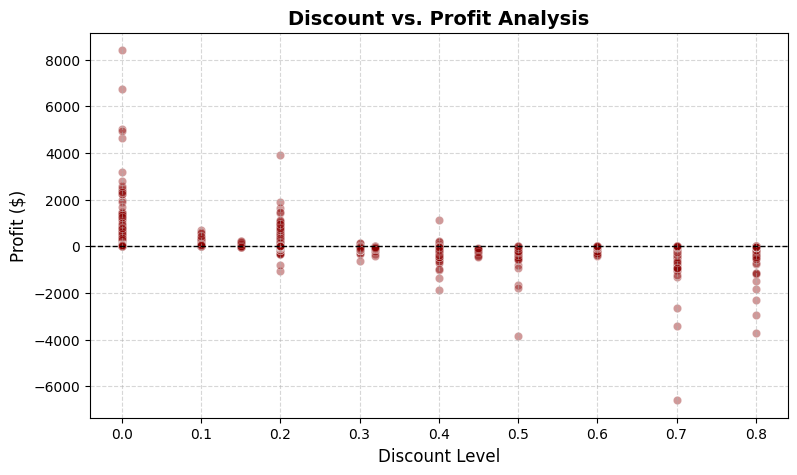

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.scatterplot(data=a, x='Discount', y='Profit', alpha=0.4, color='darkred')
plt.title('Discount vs. Profit Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Discount Level', fontsize=12)
plt.ylabel('Profit ($)', fontsize=12)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Interpretation:**
- The scatter plot clearly shows that as the discount level increases (especially beyond 20-30%), profits drop significantly below the zero line, resulting in heavy financial losses for the business due to unmonitored discounting.

## 10 Regional Profitability Comparison
**Library Used:** Seaborn & Matplotlib  
**Objective:** Compare profit across regions, not just sales, to identify regions with strong or weak profitability.

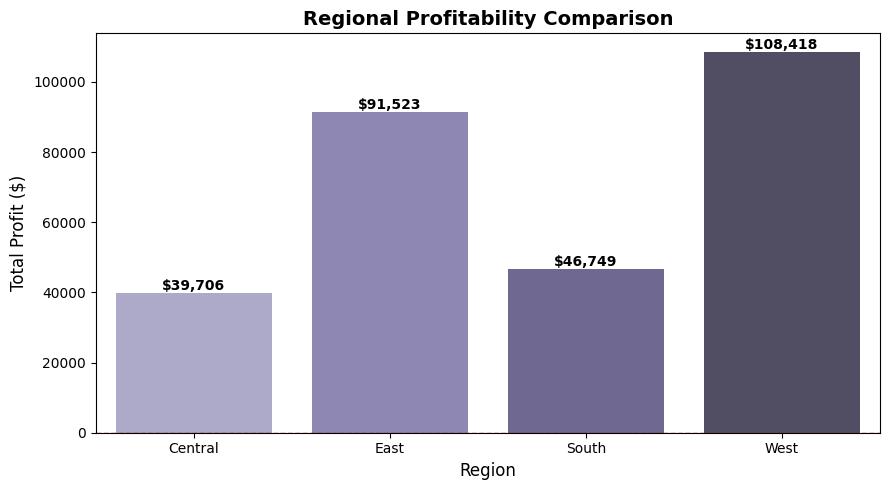

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
region_profit = a.groupby('Region')['Profit'].sum().reset_index()

ax = sns.barplot(data=region_profit, x='Region', y='Profit', palette='Purples_d', hue='Region', legend=False)
plt.title('Regional Profitability Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Total Profit ($)', fontsize=12)
plt.axhline(0, color='red', linestyle='--', linewidth=1)

for p in ax.patches:
    ax.annotate(f"${p.get_height():,.0f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom' if p.get_height()>=0 else 'top',
                fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretation:**
- While the West and East regions lead in overall sales, the West region generates the highest net profit. In contrast, the Central region shows relatively lower profitability compared to its sales volume, pointing to heavier discounting in that area.

## Top 10 Products by Sales
**Library Used:** Seaborn & Matplotlib  
**Objective:** Use a horizontal bar chart to identify the best-performing products by total sales.

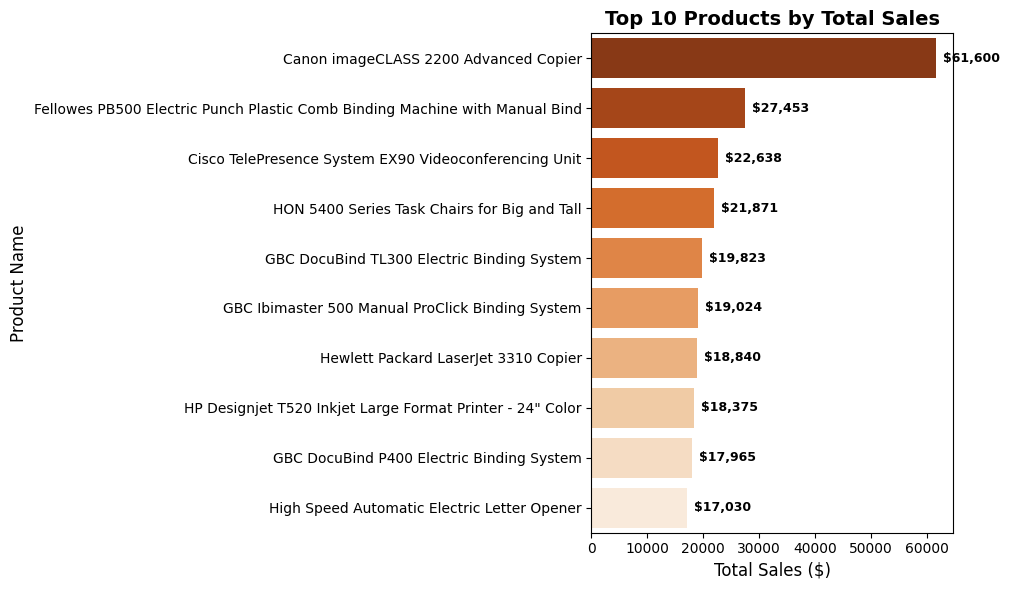

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
top_products = a.groupby('Product Name')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False).head(10)

ax = sns.barplot(data=top_products, y='Product Name', x='Sales', palette='Oranges_r', hue='Product Name', legend=False)
plt.title('Top 10 Products by Total Sales', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales ($)', fontsize=12)
plt.ylabel('Product Name', fontsize=12)

for p in ax.patches:
    ax.annotate(f"${p.get_width():,.0f}",
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                va='center', xytext=(5, 0), textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

**Interpretation:**
- High-end office equipment and technology products (such as Cisco TelePresence systems and premium copiers) dominate the top 10 list, driving the highest gross sales for the store.

# STEP 5: Insight Summary & Business Recommendations

## Conclusion & Business Insights
Based on the comprehensive Exploratory Data Analysis (EDA) and newly added profitability assessments on the Sample Superstore dataset, here are the core findings and strategic recommendations:

### Key Findings:
1. **Sales & Category Dominance:** Technology and Furniture product categories generate the highest total sales volume and revenue share. However, sales share alone does not establish profitability.
2. **Profitability & Discount Impact:** The scatter plot and sub-category profit analysis reveal that heavy discounting (especially beyond 20–30%) severely erodes profit margins, resulting in substantial financial losses in specific sub-categories like Tables, Bookcases, and Supplies (despite decent sales volumes). High-profit generation is led by sub-categories such as Copiers, Phones, and Accessories.
3. **Regional Profitability Variances:** While the West and East regions lead in gross sales, the West region secures the highest net profit. In contrast, the Central region shows relatively lower profitability compared to its high sales volume, pointing to heavy discounting issues in that region.
4. **Top-Performing Products:** High-end office equipment and technology systems (such as Cisco TelePresence and premium copiers) dominate the top 10 list by gross sales.
5. **Correlation Insights:** The correlation heatmap confirms strong relationships among meaningful numerical features, demonstrating how pricing, quantities, and discount rates interact directly with net profit margins.

### Business Recommendations:
- **Optimize Discount Thresholds:** Re-evaluate and cap high-discount policies, particularly for loss-making sub-categories (Tables, Bookcases, and Supplies), to prevent high-revenue orders from resulting in net financial losses.
- **Focus on High-Margin Categories:** Allocate marketing budgets and inventory support toward highly profitable segments like Technology and high-performing sub-categories (Copiers and Phones).
- **Targeted Regional Strategies:** Investigate the pricing and discount structures in the Central region to align profitability with its strong sales volume, mirroring the success seen in the West.
- **Inventory & Sales Alignment:** Capitalize on seasonal trends and top-selling product lines while restructuring low-margin or loss-making products to maximize overall business ROI.